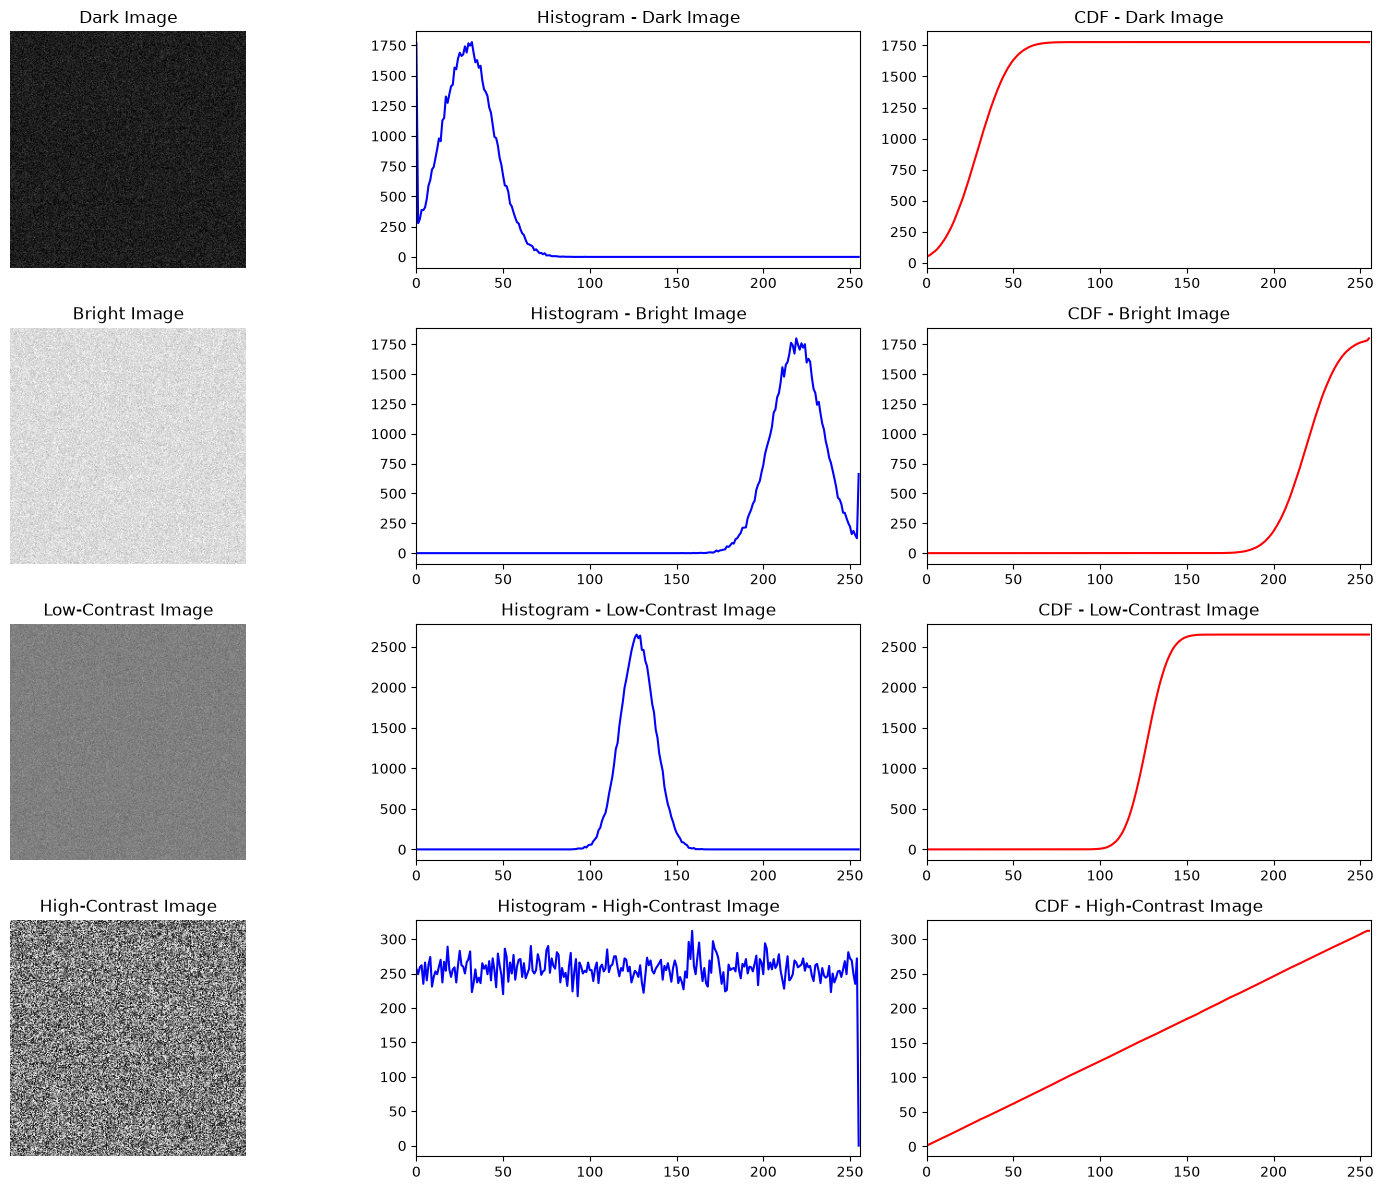

In [3]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Generate synthetic 256x256 test images
np.random.seed(42)

# a. Dark image (pixel values clustered near 0)
dark_img = np.random.normal(loc=30, scale=15, size=(256, 256))
dark_img = np.clip(dark_img, 0, 255).astype(np.uint8)

# b. Bright image (pixel values clustered near 255)
bright_img = np.random.normal(loc=220, scale=15, size=(256, 256))
bright_img = np.clip(bright_img, 0, 255).astype(np.uint8)

# c. Low-contrast image (narrow dynamic range in the middle)
low_contrast_img = np.random.normal(loc=128, scale=10, size=(256, 256))
low_contrast_img = np.clip(low_contrast_img, 0, 255).astype(np.uint8)

# d. High-contrast image (wide dynamic range using full 0-255 spectrum)
high_contrast_img = np.random.uniform(low=0, high=255, size=(256, 256)).astype(
    np.uint8
)

images = {
    "Dark Image": dark_img,
    "Bright Image": bright_img,
    "Low-Contrast Image": low_contrast_img,
    "High-Contrast Image": high_contrast_img,
}

# Plotting Image, Histogram, and CDF
fig, axes = plt.subplots(4, 3, figsize=(15, 12))

for i, (title, img) in enumerate(images.items()):
    # Calculate Histogram
    hist, bins = np.histogram(img.flatten(), 256, [0, 256])

    # Calculate Cumulative Distribution Function (CDF)
    cdf = hist.cumsum()
    cdf_normalized = (
        cdf * float(hist.max()) / cdf.max()
    )  # scale for visualization

    # Display Image
    axes[i, 0].imshow(img, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(title)
    axes[i, 0].axis("off")

    # Display Histogram
    axes[i, 1].plot(hist, color="blue")
    axes[i, 1].set_title(f"Histogram - {title}")
    axes[i, 1].set_xlim([0, 256])

    # Display CDF
    axes[i, 2].plot(cdf_normalized, color="red")
    axes[i, 2].set_title(f"CDF - {title}")
    axes[i, 2].set_xlim([0, 256])

plt.tight_layout()
plt.show()

Q2


 Contrast Enhancement Operations & Challenge

Max pixel difference between manual CDF and cv2.equalizeHist(): 1


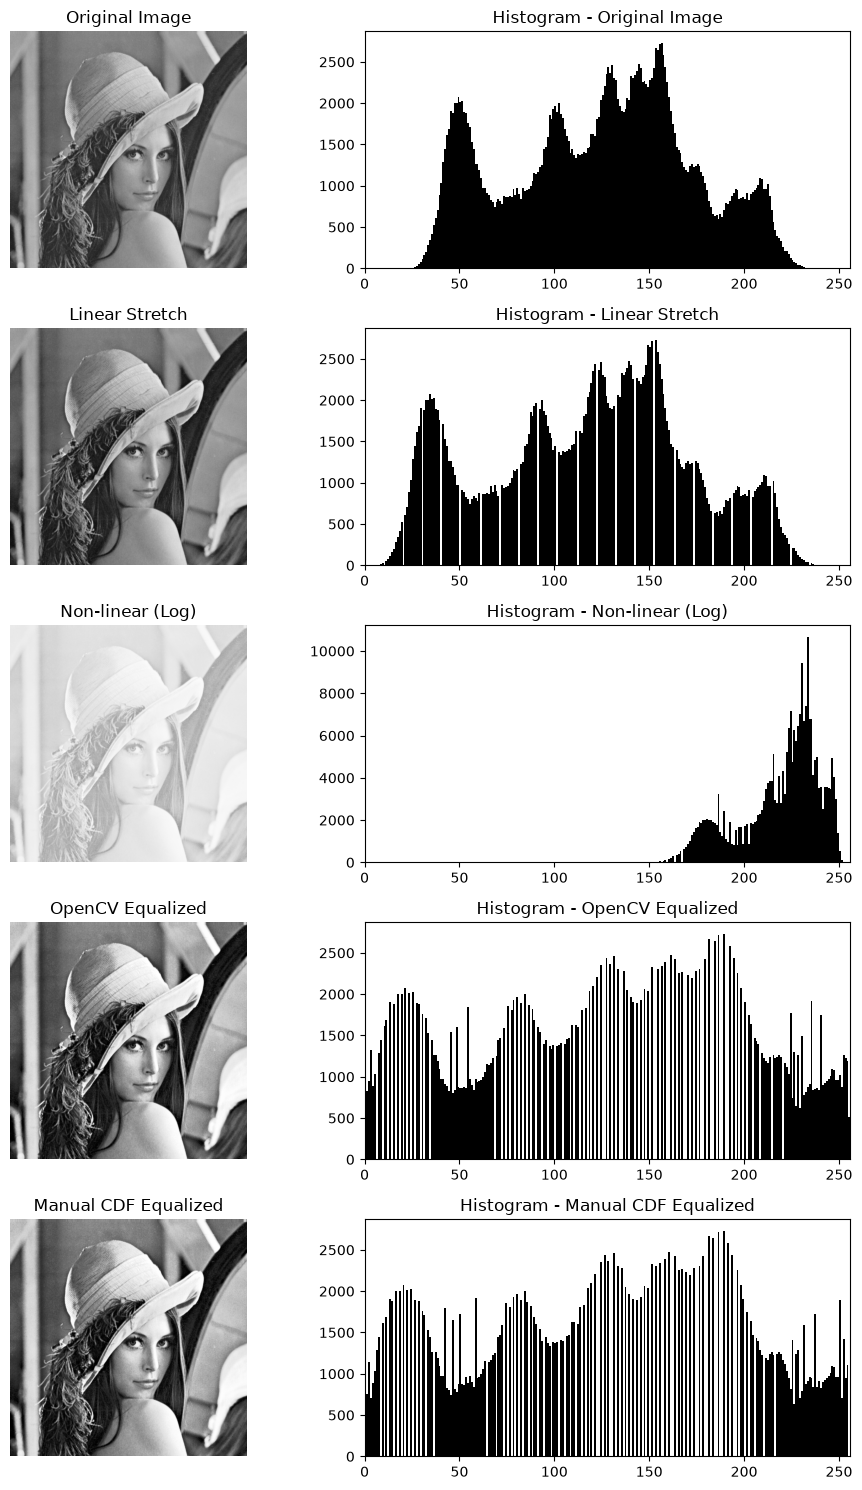

In [4]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Load or generate a low-contrast image to demonstrate enhancement
img = cv2.imread("lenna.png", cv2.IMREAD_GRAYSCALE)
if img is None:  # Fallback synthetic low-contrast image if lenna.png isn't available
    img = np.random.normal(loc=120, scale=15, size=(256, 256))
    img = np.clip(img, 0, 255).astype(np.uint8)

# --------------------------------------------------
# a. Linear Contrast Stretching
# --------------------------------------------------
r_min, r_max = np.min(img), np.max(img)
linear_stretched = (img - r_min) * (255.0 / (r_max - r_min))
linear_stretched = np.clip(linear_stretched, 0, 255).astype(np.uint8)

# --------------------------------------------------
# b. Non-Linear Contrast Stretching (Log Transform)
# --------------------------------------------------
c = 255 / np.log(1 + np.max(img))
nonlinear_stretched = c * np.log(1 + np.float32(img))
nonlinear_stretched = np.clip(nonlinear_stretched, 0, 255).astype(np.uint8)

# --------------------------------------------------
# c. Histogram Equalization (OpenCV Built-in)
# --------------------------------------------------
equalized_cv2 = cv2.equalizeHist(img)

# --------------------------------------------------
# Challenge: Manual Histogram Equalization using CDF
# --------------------------------------------------
hist, bins = np.histogram(img.flatten(), 256, [0, 256])
cdf = hist.cumsum()

# Mask zero values in CDF to avoid division by zero during normalization
cdf_m = np.ma.masked_equal(cdf, 0)
# Equalization formula: h(v) = round(((cdf(v) - cdf_min) / (N - 1)) * (L - 1))
cdf_m = (cdf_m - cdf_m.min()) * 255 / (cdf_m.max() - cdf_m.min())
cdf_final = np.ma.filled(cdf_m, 0).astype("uint8")

# Map pixel values using the calculated lookup table
equalized_manual = cdf_final[img]

# Check equality between manual implementation and OpenCV built-in
diff = np.abs(equalized_manual.astype(int) - equalized_cv2.astype(int))
print(f"Max pixel difference between manual CDF and cv2.equalizeHist(): {np.max(diff)}")

# --------------------------------------------------
# Display Comparisons
# --------------------------------------------------
methods = [
    ("Original Image", img),
    ("Linear Stretch", linear_stretched),
    ("Non-linear (Log)", nonlinear_stretched),
    ("OpenCV Equalized", equalized_cv2),
    ("Manual CDF Equalized", equalized_manual),
]

fig, axes = plt.subplots(len(methods), 2, figsize=(10, 15))

for i, (title, result_img) in enumerate(methods):
    # Image Display
    axes[i, 0].imshow(result_img, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(title)
    axes[i, 0].axis("off")

    # Histogram Display
    axes[i, 1].hist(result_img.flatten(), bins=256, range=[0, 256], color="black")
    axes[i, 1].set_title(f"Histogram - {title}")
    axes[i, 1].set_xlim([0, 256])

plt.tight_layout()
plt.show()